<a href="https://colab.research.google.com/github/J3remy1/east-river-water-quality/blob/main/notebooks/04_estuary_2020_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SHEETS = {
    2022: "1ymbsUO2C1Lsl3Ng2fyMlGJpYaY8LhgC6hn5j7dik3fc",
    2023: "1hsqDKeA2el8RLtQfp75kIO8hIPIF4asitczLqyjz9fI",
    2024: "1FQBlW--tZvSEUqFZNcAGb0uv_6caEf_d3VkOdFm1CZI",
    2025: "1OWoGztuQ9yhjH6Zk2wkHTvdFntbIvfU11MXhp4X20og",
}
FILES = {
    2020: "1uYFm_xP8EatyS3gSSNDjFpCwn8v1sfn1",
    2021: "1d8hvgiuuev-DorHlbCwbgdJ5i7lgkxnD",
}
HEADER_ROW = {2020: 1, 2021: 1}

def source(year):
    if year in SHEETS:
        return f"https://docs.google.com/spreadsheets/d/{SHEETS[year]}/export?format=xlsx"
    return f"https://drive.google.com/uc?export=download&id={FILES[year]}"

In [2]:
def to_number(value):
    if pd.isna(value):
        return np.nan
    nums = re.findall(r"\d+\.?\d*", str(value))
    if len(nums) == 1:
        return float(nums[0])
    if len(nums) == 2:
        return (float(nums[0]) + float(nums[1])) / 2
    return np.nan

def to_percent(value):
    x = to_number(value)
    if x <= 2:
        return x * 100
    return x

def first_number(value):
    if pd.isna(value):
        return np.nan
    nums = re.findall(r"-?\d+\.?\d*", str(value))
    if nums:
        return float(nums[0])
    return np.nan

def do_saturation(temp_c, salinity_ppt):
    """Dissolved oxygen at saturation, mg/L, 1 atm (Weiss 1970)."""
    T = temp_c + 273.15
    A1, A2, A3, A4 = -173.4292, 249.6339, 143.3483, -21.8492
    B1, B2, B3 = -0.033096, 0.014259, -0.0017000
    ln_c = (A1 + A2 * (100 / T) + A3 * np.log(T / 100) + A4 * (T / 100)
            + salinity_ppt * (B1 + B2 * (T / 100) + B3 * (T / 100) ** 2))
    return np.exp(ln_c) * 1.42903

def find_col(columns, *options):
    for option in options:
        for col in columns:
            if option in col:
                return col
    raise KeyError(f"none of {options} found")

def get_table(tabs, name, header_row=0):
    raw = tabs[name]
    table = raw.iloc[header_row + 1:].copy()
    table.columns = [str(c).strip() for c in raw.iloc[header_row]]
    return table

In [3]:
def load_year(year):
    tabs = pd.read_excel(source(year), sheet_name=None, header=None)
    tabs = {name.strip(): t for name, t in tabs.items()}

    chem = get_table(tabs, "Chemistry", HEADER_ROW.get(year, 0))
    cols = list(chem.columns)
    df = pd.DataFrame({
        "year": year,
        "river": chem.iloc[:, 0].astype("string").str.strip(),
        "rm": chem.iloc[:, 1].apply(first_number),
        "site": chem.iloc[:, 2],
        "temp_c": pd.to_numeric(chem[find_col(cols, "Reading (Celsius)", "Temperature C")], errors="coerce"),
        "do_ppm": chem[find_col(cols, "DO: Reading", "Dissolved Oxygen ppm")].apply(to_number),
        "sat_reported": chem[find_col(cols, "Saturation")].apply(to_percent),
    })
    df = df.dropna(subset=["river"])

    parts = []
    for name in ["Standardized Salinity", "Partner Salinity"]:
        if name in tabs:
            s = get_table(tabs, name)
            total = s.iloc[:, list(s.columns).index("Total Salinity ppm")]
            parts.append(pd.DataFrame({
                "river": s.iloc[:, 0].astype("string").str.strip(),
                "rm": s.iloc[:, 1].apply(first_number),
                "salinity_ppt": pd.to_numeric(total, errors="coerce") / 1000,
            }))
    sal = pd.concat(parts)
    sal_by_rm = sal.groupby(["river", "rm"])["salinity_ppt"].median().reset_index()
    return df.merge(sal_by_rm, on=["river", "rm"], how="left")

data = pd.concat([load_year(y) for y in range(2020, 2026)], ignore_index=True)
data["sat_fresh"] = 100 * data["do_ppm"] / do_saturation(data["temp_c"], 0)
data["sat_salty"] = 100 * data["do_ppm"] / do_saturation(data["temp_c"], data["salinity_ppt"])
data.shape

(486, 10)

In [4]:
rows = []
for year, g in data.groupby("year"):
    has_all = g["sat_reported"].notna() & g["sat_fresh"].notna()
    salty = g[(g["salinity_ppt"] > 10) & has_all]
    fresh = g[(g["salinity_ppt"] < 1) & has_all]
    gap = salty["sat_reported"] - salty["sat_fresh"]
    rows.append({
        "year": year,
        "salty_sites": len(salty),
        "gap_vs_fresh": gap.median(),
        "gap_vs_corrected": (salty["sat_reported"] - salty["sat_salty"]).median(),
        "within_5_of_fresh": (gap.abs() <= 5).sum(),
        "fresh_sites": len(fresh),
        "fresh_gap": (fresh["sat_reported"] - fresh["sat_fresh"]).median(),
    })
summary = pd.DataFrame(rows).set_index("year")
summary.round(1)

,salty_sites,gap_vs_fresh,gap_vs_corrected,within_5_of_fresh,fresh_sites,fresh_gap
year,,,,,,
2020,17,-0.6,-7.8,14,8,-2.0
2021,8,0.1,-12.3,6,10,-0.8
2022,15,-0.4,-12.7,9,7,-1.1
2023,13,-1.4,-13.6,8,9,-2.8
2024,25,-1.4,-11.6,19,18,-0.2
2025,22,-0.3,-11.4,17,13,-0.5


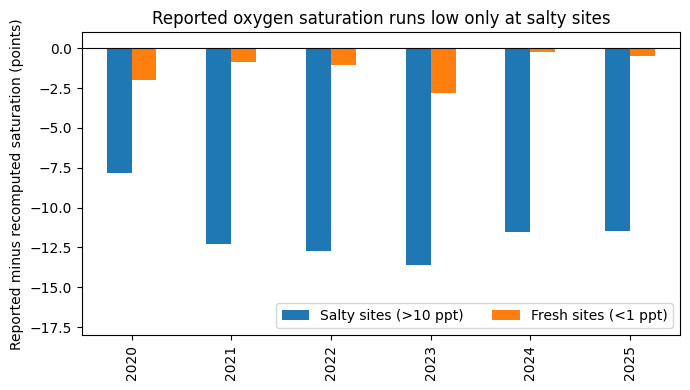

In [5]:
plot_data = summary[["gap_vs_corrected", "fresh_gap"]].rename(columns={
    "gap_vs_corrected": "Salty sites (>10 ppt)",
    "fresh_gap": "Fresh sites (<1 ppt)",
})
ax = plot_data.plot(kind="bar", figsize=(7, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Reported minus recomputed saturation (points)")
ax.set_xlabel("")
ax.set_title("Reported oxygen saturation runs low only at salty sites")
ax.set_ylim(-18, 1)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.savefig("saturation_gap_2020_2025.png", dpi=200)
plt.show()

In [6]:
data.to_csv("estuary_2020_2025.csv", index=False)

**Findings.** Across six years (2020–2025), 100 readings from salty sites (above 10 ppt) had a reported saturation, a temperature, and a dissolved oxygen value. 73 of them fall within 5 points of the value a freshwater table gives. Compared with a salinity-corrected calculation (Weiss 1970), the reported values run low every year, by a median of 7.8 to 13.6 points. At fresh sites (below 1 ppt, 65 readings), the same comparison shows a median gap of 0.2 to 2.8 points.

This is a known limitation, not a hidden error. The program’s own guide says the saturation chart is based on fresh water and does not account for salinity. What this notebook adds is the size of the effect.

**Limits.** Salinity is matched to each site by river and river mile, using the median when several readings exist. Three rows have river miles that my parser reads incorrectly; none is a salty site. Readings entered as a range are averaged.
   Source: [Interpreting Your Data, answer key](https://www.ldeo.columbia.edu/edu/k12/snapshotday/activities/InterpretingYourDataANS.pdf), Lamont-Doherty Earth Observatory.